# Predicción de nacimientos en Colombia por departamento para 2024

**Aplicaciones I · SMTART84 · Grupo 2 · Universidad de La Salle · Maestría en Inteligencia Artificial**

**Integrantes**
1. Juan Camilo Narváez Sánchez
2. Ronald Andrés García Díaz
3. Adrián Felipe Deulofeut Gil

## A) Introducción

**Propósito.** Estimar el número de nacidos vivos que tendrá en **2024** cada uno de los 32 departamentos de Colombia y Bogotá D. C., según la **residencia habitual de la madre**, con un modelo de *Machine Learning* entrenado con los registros de nacimientos de **2020, 2021, 2022 y 2023**.

**Datos.** Microdatos de nacimientos de las *Estadísticas Vitales (EEVV)* del DANE, una fila por cada certificado de nacido vivo, descargados de los cuatro catálogos indicados en la actividad (2020, 2021, 2022 y 2023).

**Librerías principales.**
- **pandas**: lectura de los microdatos, limpieza y construcción del panel departamento × año × mes.
- **NumPy**: cálculos numéricos y transformaciones.
- **scikit-learn**: modelos de regresión, codificación de variables categóricas y métricas de evaluación.
- **Matplotlib**: gráficos.

### ¿Por qué es útil la predicción?

**¿Quién usaría una predicción de nacimientos por departamento?** Usuarios estratégicos como el Ministerio de Salud, el Ministerio de Educación, el ICBF, las secretarías de salud locales, así como EPS y redes hospitalarias.

**¿Para qué decisiones concretas?** Para la planificación de recursos físicos y financieros, tales como el dimensionamiento de camas en salas de obstetricia y pediatría, la estimación de dosis para la compra de vacunas, y la planeación futura de cupos para jardines infantiles y colegios.

**¿Por qué importa ahora, con la natalidad cayendo?** Porque ante una contracción sostenida de los nacimientos, contar con predicciones precisas evita la sobreinversión y el alto costo de mantener infraestructura o personal ocioso, permitiendo redirigir esos recursos hacia otras necesidades demográficas.

In [1]:
import zipfile
from pathlib import Path
from urllib.request import Request, urlopen

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import HTML, Markdown, display
from matplotlib.ticker import FuncFormatter
from sklearn.base import clone
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder

AZUL, NARANJA, GRIS = "#006478", "#b34716", "#7a7a7a"


def entero(valor):
    """Formato colombiano: 12.345"""
    return f"{valor:,.0f}".replace(",", ".")


def decimal(valor, digitos=1):
    """Formato colombiano: 12.345,6"""
    return f"{valor:,.{digitos}f}".translate(str.maketrans(",.", ".,"))


def mostrar(tabla, formatos=None):
    # HTML estático para que se vean todas las filas en Colab y en la exportación .html
    display(HTML(tabla.to_html(index=False, formatters=formatos, na_rep="—")))


eje_miles = FuncFormatter(lambda valor, posicion: entero(valor))
MESES = ["enero", "febrero", "marzo", "abril", "mayo", "junio", "julio",
         "agosto", "septiembre", "octubre", "noviembre", "diciembre"]

## B) Preprocesamiento de los datos

### Fuente

| Año | Catálogo del DANE | Archivo usado |
|---|---|---|
| 2020 | [Estadísticas Vitales – EEVV – 2020](https://microdatos.dane.gov.co/index.php/catalog/732) | `nac2020.csv` |
| 2021 | [Estadísticas Vitales – EEVV – 2021](https://microdatos.dane.gov.co/index.php/catalog/775) | `nac2021.csv` |
| 2022 | [Estadísticas Vitales – EEVV – 2022](https://microdatos.dane.gov.co/index.php/catalog/807) | `nac2022.csv` |
| 2023 | [Estadísticas Vitales – EEVV – 2023](https://microdatos.dane.gov.co/index.php/catalog/876) | `BD-EEVV-Nacimientos-2023.csv` |

Cada catálogo publica tres bases (nacimientos, defunciones no fetales y defunciones fetales) en CSV, SPSS y Stata. Solo se usa la base de **nacimientos en CSV**. Para que el cuaderno sea reproducible en Colab, cada CSV se guardó sin modificar en un zip propio (`nac2020.zip` … `nac2023.zip`).

**Cómo cargar los archivos en Colab.** El cuaderno busca los zips en la carpeta `datos/` o en `/content`. Si no los encuentra, los descarga de `URL_DATOS`. Otra opción: abrir **Archivos** (icono de carpeta) → **Subir al almacenamiento de la sesión** y subir los cuatro zips.

### Variables leídas

De las 37 a 39 variables de cada base se leen solo las necesarias, todas como texto para conservar los ceros a la izquierda de los códigos:

| Variable | Significado (diccionario del DANE) |
|---|---|
| `CODPTORE` | Departamento de residencia habitual de la madre |
| `ANO`, `MES` | Año y mes de ocurrencia del nacimiento |
| `EDAD_MADRE` | Grupo de edad de la madre (1 = 10–14 años, 2 = 15–19, …, 99 = sin información) |
| `AREA_RES` | Área de residencia de la madre (1 = cabecera municipal, 2 = centro poblado, 3 = rural disperso) |

### Limpieza

1. Se comprueba que cada base tenga exactamente el total de nacimientos publicado por el DANE y que todos los registros sean del año y de los meses 1 a 12.
2. Se excluyen los nacimientos **sin departamento de residencia en Colombia** (`CODPTORE` vacío): madres residentes en el exterior o sin información. Se informan en la tabla de conciliación y no se redistribuyen.
3. Se agregan los registros en un **panel departamento × año × mes** (33 territorios × 4 años × 12 meses = 1.584 filas). Bogotá D. C. (11) se trata como territorio propio, separado de Cundinamarca (25).

In [2]:
# Si los zips están en otro sitio (por ejemplo, el repositorio de GitHub del grupo), cambiar esta URL.
URL_DATOS = "https://raw.githubusercontent.com/adeulofeut/Aplicaciones1/actividad5/datos/"
CARPETAS = [Path("datos"), Path("/content/datos"), Path("/content"), Path(".")]
ANIOS = [2020, 2021, 2022, 2023]
COLUMNAS = ["CODPTORE", "ANO", "MES", "EDAD_MADRE", "AREA_RES"]

# Totales nacionales de nacimientos publicados por el DANE (cifras definitivas).
TOTAL_DANE = {2020: 629_402, 2021: 616_914, 2022: 573_625, 2023: 515_549}

DIVIPOLA = {
    "05": "Antioquia", "08": "Atlántico", "11": "Bogotá D. C.", "13": "Bolívar",
    "15": "Boyacá", "17": "Caldas", "18": "Caquetá", "19": "Cauca",
    "20": "Cesar", "23": "Córdoba", "25": "Cundinamarca", "27": "Chocó",
    "41": "Huila", "44": "La Guajira", "47": "Magdalena", "50": "Meta",
    "52": "Nariño", "54": "Norte de Santander", "63": "Quindío",
    "66": "Risaralda", "68": "Santander", "70": "Sucre", "73": "Tolima",
    "76": "Valle del Cauca", "81": "Arauca", "85": "Casanare",
    "86": "Putumayo", "88": "San Andrés y Providencia",
    "91": "Amazonas", "94": "Guainía", "95": "Guaviare", "97": "Vaupés", "99": "Vichada",
}


def obtener_zip(anio):
    """Devuelve la ruta local de nac<anio>.zip; si no existe, lo descarga de URL_DATOS."""
    nombre = f"nac{anio}.zip"
    for carpeta in CARPETAS:
        if (carpeta / nombre).exists():
            return carpeta / nombre
    destino = Path("datos") / nombre
    destino.parent.mkdir(exist_ok=True)
    try:
        with urlopen(Request(URL_DATOS + nombre, headers={"User-Agent": "Mozilla/5.0"}), timeout=180) as respuesta:
            destino.write_bytes(respuesta.read())
    except OSError as error:
        raise RuntimeError(f"No se encontró {nombre}. Súbelo a /content y repite la celda.") from error
    return destino


def leer_anio(anio):
    """Lee el CSV de nacimientos de un año y verifica su integridad."""
    with zipfile.ZipFile(obtener_zip(anio)) as archivo_zip:
        csv = next(nombre for nombre in archivo_zip.namelist() if nombre.lower().endswith(".csv"))
        with archivo_zip.open(csv) as flujo:
            datos = pd.read_csv(flujo, usecols=COLUMNAS, dtype=str)
    if len(datos) != TOTAL_DANE[anio]:
        raise ValueError(f"{anio}: {len(datos)} registros, el DANE publica {TOTAL_DANE[anio]}.")
    if not datos["ANO"].eq(str(anio)).all():
        raise ValueError(f"{anio}: hay registros de otro año.")
    if not datos["MES"].astype(int).between(1, 12).all():
        raise ValueError(f"{anio}: hay meses fuera de rango.")
    return datos


registros = pd.concat([leer_anio(anio) for anio in ANIOS], ignore_index=True)
registros["anio"] = registros["ANO"].astype(int)
registros["mes"] = registros["MES"].astype(int)
registros["codigo"] = registros["CODPTORE"].str.strip().str.zfill(2)
registros.loc[registros["CODPTORE"].isna(), "codigo"] = pd.NA
print(f"Registros leídos: {entero(len(registros))}")
mostrar(registros.head())

Registros leídos: 2.335.490


ANO,MES,EDAD_MADRE,CODPTORE,AREA_RES,anio,mes,codigo
2020,11,4,44,3,2020,11,44
2020,10,4,44,3,2020,10,44
2020,10,5,44,3,2020,10,44
2020,04,5,44,3,2020,4,44
2020,08,3,44,3,2020,8,44


In [3]:
# Conciliación: total del DANE = nacimientos con departamento de residencia + excluidos
con_departamento = registros["codigo"].isin(DIVIPOLA)
desconocidos = set(registros.loc[registros["codigo"].notna() & ~con_departamento, "codigo"])
assert not desconocidos, f"Códigos de departamento no reconocidos: {desconocidos}"

conciliacion = (registros.assign(incluido=con_departamento)
                .groupby("anio")["incluido"].agg(total="size", incluidos="sum").reset_index())
conciliacion["excluidos"] = conciliacion["total"] - conciliacion["incluidos"]
conciliacion["% excluido"] = 100 * conciliacion["excluidos"] / conciliacion["total"]
conciliacion.columns = ["Año", "Total DANE", "Con departamento de residencia",
                        "Exterior o sin información", "% excluido"]
mostrar(conciliacion, {**{c: entero for c in conciliacion.columns[1:4]}, "% excluido": decimal})

nacimientos = registros.loc[con_departamento].copy()

# Panel completo departamento × año × mes (si una combinación no tuviera registros, vale 0)
indice = pd.MultiIndex.from_product([sorted(DIVIPOLA), ANIOS, range(1, 13)],
                                    names=["codigo", "anio", "mes"])
panel = (nacimientos.groupby(["codigo", "anio", "mes"]).size()
         .reindex(indice, fill_value=0).rename("nacimientos").reset_index())
panel["departamento"] = panel["codigo"].map(DIVIPOLA)

assert len(panel) == 33 * 4 * 12
assert panel.groupby("anio")["nacimientos"].sum().eq(conciliacion.set_index("Año")["Con departamento de residencia"]).all()
print(f"Panel mensual: {len(panel)} filas · {panel['codigo'].nunique()} territorios · años {ANIOS[0]}–{ANIOS[-1]}")

Año,Total DANE,Con departamento de residencia,Exterior o sin información,% excluido
2020,629.402,619.602,9.800,"1,6"
2021,616.914,608.083,8.831,"1,4"
2022,573.625,567.227,6.398,"1,1"
2023,515.549,508.299,7.250,"1,4"


Panel mensual: 1584 filas · 33 territorios · años 2020–2023


## C) Exploración de los datos

Se revisan tres aspectos que orientan el modelo: la **tendencia** nacional entre años, la **estacionalidad** dentro del año y las **diferencias entre departamentos**.

Año,Nacimientos,Variación anual (%)
2020,619.602,—
2021,608.083,"-1,9"
2022,567.227,"-6,7"
2023,508.299,"-10,4"


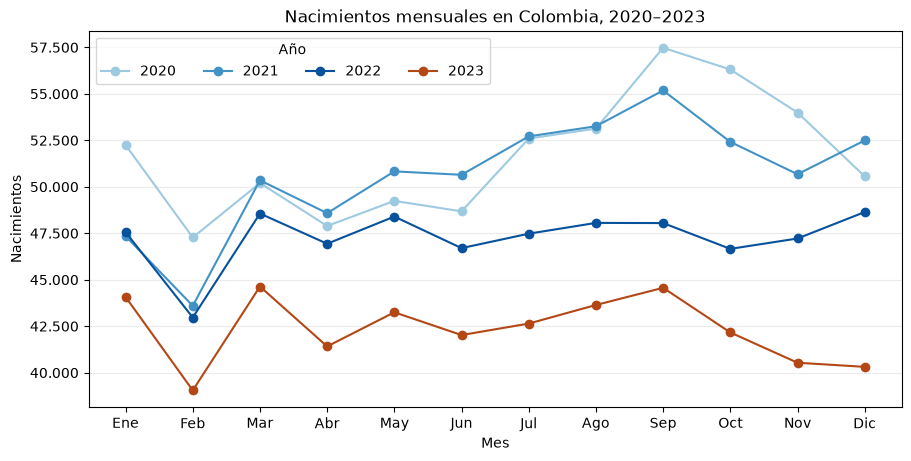

Entre 2020 y 2023 los nacimientos con residencia en Colombia pasaron de **619.602** a **508.299** (**-18,0 %**). En promedio, el mes con más nacimientos es **septiembre** y el de menos, **febrero**.

In [4]:
anual_nacional = panel.groupby("anio")["nacimientos"].sum()
tabla_nacional = pd.DataFrame({"Año": anual_nacional.index, "Nacimientos": anual_nacional.values,
                               "Variación anual (%)": anual_nacional.pct_change().mul(100).values})
mostrar(tabla_nacional, {"Nacimientos": entero, "Variación anual (%)": decimal})

fig, ax = plt.subplots(figsize=(9, 4.5), layout="constrained")
mensual = panel.pivot_table(index="mes", columns="anio", values="nacimientos", aggfunc="sum")
for anio, color in zip(ANIOS, ["#9ecae1", "#4292c6", "#08519c", NARANJA]):
    ax.plot(mensual.index, mensual[anio], marker="o", color=color, label=str(anio))
ax.set(title="Nacimientos mensuales en Colombia, 2020–2023",
       xlabel="Mes", ylabel="Nacimientos", xticks=range(1, 13),
       xticklabels=["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"])
ax.yaxis.set_major_formatter(eje_miles)
ax.grid(axis="y", alpha=0.25)
ax.legend(title="Año", ncol=4)
plt.show()

cambio_total = 100 * (anual_nacional[2023] / anual_nacional[2020] - 1)
mes_max = mensual.mean(axis=1).idxmax()
mes_min = mensual.mean(axis=1).idxmin()
display(Markdown(
    f"Entre 2020 y 2023 los nacimientos con residencia en Colombia pasaron de **{entero(anual_nacional[2020])}** "
    f"a **{entero(anual_nacional[2023])}** (**{decimal(cambio_total)} %**). En promedio, el mes con más "
    f"nacimientos es **{MESES[mes_max - 1]}** y el de menos, **{MESES[mes_min - 1]}**."
))

### Interpretación: tendencia nacional y estacionalidad

**¿La caída es igual todos los años o se acelera?** La caída no es constante; se está acelerando progresivamente. Los datos muestran que pasó de una leve contracción del -1,9 % en 2021 a una caída profunda del -10,4 % en 2023.

**¿Por qué febrero podría ser el más bajo y septiembre el más alto?** Febrero registra el mínimo principalmente por un factor mecánico: tiene menos días (28 o 29) comparado con el resto. Septiembre es el mes con más nacimientos porque refleja un patrón cultural persistente: corresponde a las concepciones ocurridas entre diciembre y enero, durante las festividades de fin de año.

**¿Por qué conviene que el modelo conozca el mes?** Porque existe un patrón cíclico y muy marcado cada año. Incluir el mes permite al modelo aprender esta fuerte estacionalidad y ajustar las predicciones hacia arriba o hacia abajo dependiendo de la época del año, mejorando la precisión mensual.

Departamento,2020,2021,2022,2023,Cambio 2020–2023 (%)
Bogotá D. C.,79.322,66.988,64.765,60.912,"-23,2"
Antioquia,71.783,70.251,66.766,59.017,"-17,8"
Valle del Cauca,46.752,45.171,40.862,36.514,"-21,9"
Atlántico,40.007,38.938,36.114,31.727,"-20,7"
Bolívar,33.416,35.802,33.895,29.953,"-10,4"
Cundinamarca,34.859,32.009,31.155,29.061,"-16,6"
Santander,26.216,25.728,24.439,21.890,"-16,5"
Córdoba,24.767,25.975,24.207,21.080,"-14,9"
La Guajira,23.562,25.254,22.139,20.333,"-13,7"
Magdalena,24.042,23.885,21.839,19.865,"-17,4"


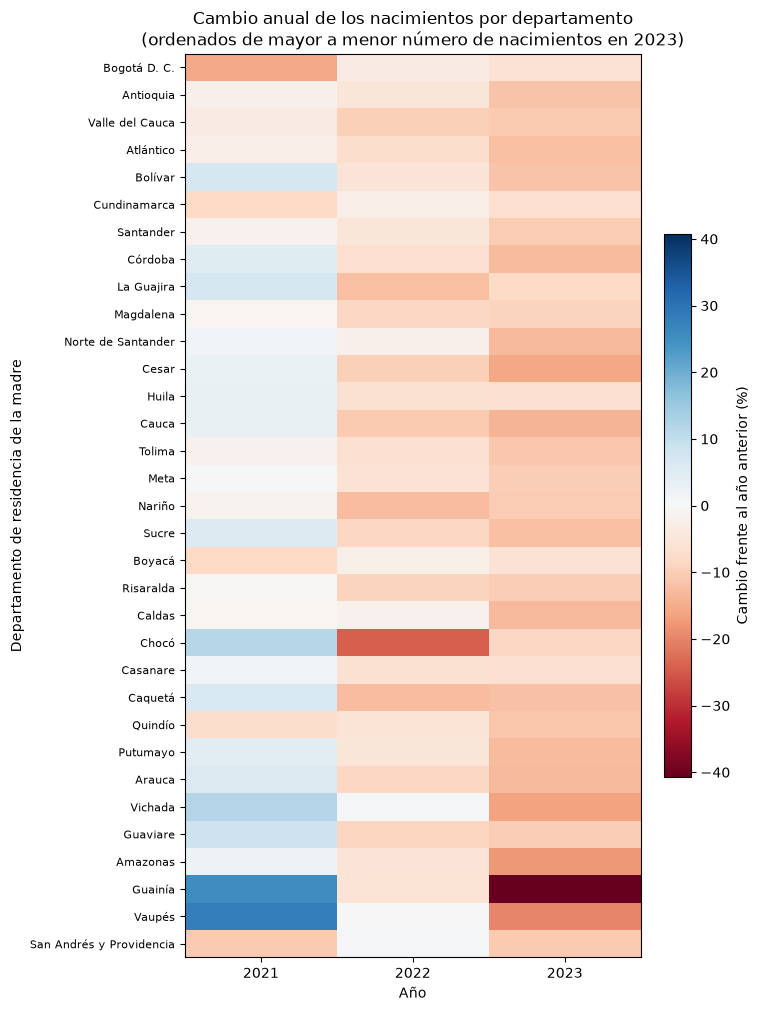

**32 de 33** territorios tuvieron menos nacimientos en 2023 que en 2020. La mayor caída fue en **Guainía** (-29,8 %) y el menor cambio en **Vaupés** (2,7 %). Los tamaños son muy distintos: Bogotá D. C. registró 60.912 nacimientos en 2023 y San Andrés y Providencia, 608.

In [5]:
anual = panel.groupby(["codigo", "departamento", "anio"], as_index=False)["nacimientos"].sum()
por_depto = anual.pivot(index="departamento", columns="anio", values="nacimientos")
por_depto["Cambio 2020–2023 (%)"] = 100 * (por_depto[2023] / por_depto[2020] - 1)
por_depto = por_depto.sort_values(2023, ascending=False).reset_index()
por_depto.columns.name = None
mostrar(por_depto.rename(columns={"departamento": "Departamento"}),{**{a: entero for a in ANIOS}, "Cambio 2020–2023 (%)": decimal})

cambios = (anual.pivot(index="departamento", columns="anio", values="nacimientos")
           .pct_change(axis=1).iloc[:, 1:] * 100)
cambios = cambios.loc[por_depto["departamento"]]
escala = np.abs(cambios.to_numpy()).max()
fig, ax = plt.subplots(figsize=(7.5, 10), layout="constrained")
mapa = ax.imshow(cambios, aspect="auto", cmap="RdBu", vmin=-escala, vmax=escala)
ax.set(title="Cambio anual de los nacimientos por departamento\n(ordenados de mayor a menor número de nacimientos en 2023)",
       xlabel="Año", ylabel="Departamento de residencia de la madre",
       xticks=range(cambios.shape[1]), xticklabels=cambios.columns,
       yticks=range(len(cambios)), yticklabels=cambios.index)
ax.tick_params(axis="y", labelsize=8)
fig.colorbar(mapa, ax=ax, shrink=0.6, label="Cambio frente al año anterior (%)")
plt.show()

cayeron = (por_depto["Cambio 2020–2023 (%)"] < 0).sum()
extremos = por_depto.sort_values("Cambio 2020–2023 (%)")
display(Markdown(
    f"**{cayeron} de 33** territorios tuvieron menos nacimientos en 2023 que en 2020. "
    f"La mayor caída fue en **{extremos.iloc[0]['departamento']}** ({decimal(extremos.iloc[0]['Cambio 2020–2023 (%)'])} %) "
    f"y el menor cambio en **{extremos.iloc[-1]['departamento']}** ({decimal(extremos.iloc[-1]['Cambio 2020–2023 (%)'])} %). "
    f"Los tamaños son muy distintos: {por_depto.iloc[0]['departamento']} registró {entero(por_depto.iloc[0][2023])} "
    f"nacimientos en 2023 y {por_depto.iloc[-1]['departamento']}, {entero(por_depto.iloc[-1][2023])}."
))

### Interpretación: diferencias entre departamentos

**¿La caída es generalizada o regional?** Es un fenómeno generalizado en casi todo el país, afectando a 32 de los 33 territorios analizados (con la única excepción de Vaupés).

**¿Por qué Bogotá cae más que el promedio?** Una explicación probable es que, al ser la ciudad más grande, experimenta fenómenos urbanos que aceleran la transición demográfica: mayor costo de vida, mayor nivel educativo en las mujeres, mayor participación laboral femenina y mejor acceso a métodos de planificación familiar.

**¿Qué problema crea para un modelo que haya departamentos 100 veces más grandes que otros?** Crea un problema grave de escala. Los algoritmos que minimizan errores absolutos (en número de nacimientos) se concentrarán en reducir el error en Bogotá o Antioquia porque allí un desvío suma miles, ignorando por completo la precisión en regiones pequeñas como San Andrés o Guainía.

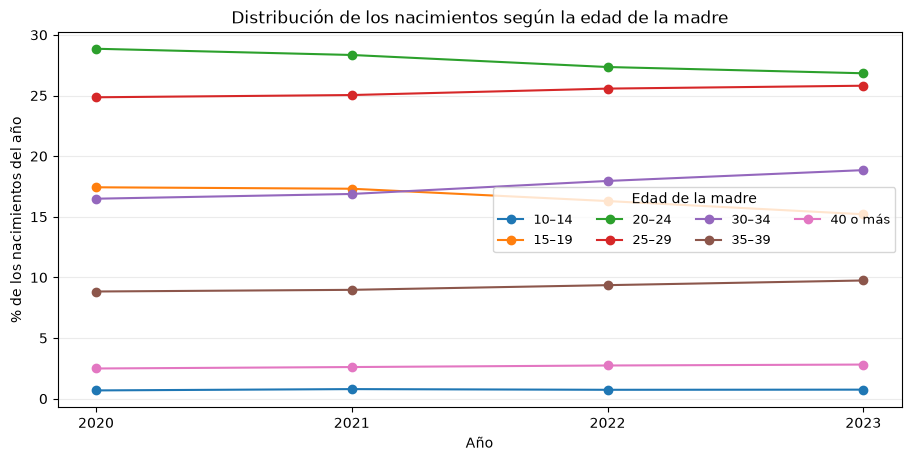

La participación de madres adolescentes (10–19 años) pasó de **18,1 %** en 2020 a **16,0 %** en 2023.

In [6]:
# Variable candidata: composición por edad de la madre
GRUPOS_EDAD = {"1": "10–14", "2": "15–19", "3": "20–24", "4": "25–29", "5": "30–34",
               "6": "35–39", "7": "40 o más", "8": "40 o más", "9": "40 o más"}
edad = (nacimientos.assign(grupo=nacimientos["EDAD_MADRE"].map(GRUPOS_EDAD).fillna("Sin información"))
        .groupby(["anio", "grupo"]).size().unstack(fill_value=0))
edad = edad[[g for g in ["10–14", "15–19", "20–24", "25–29", "30–34", "35–39", "40 o más", "Sin información"] if g in edad]]
participacion = 100 * edad.div(edad.sum(axis=1), axis=0)

fig, ax = plt.subplots(figsize=(9, 4.5), layout="constrained")
for grupo in participacion.columns.drop("Sin información", errors="ignore"):
    ax.plot(participacion.index, participacion[grupo], marker="o", label=grupo)
ax.set(title="Distribución de los nacimientos según la edad de la madre",
       xlabel="Año", ylabel="% de los nacimientos del año", xticks=ANIOS)
ax.grid(axis="y", alpha=0.25)
ax.legend(title="Edad de la madre", ncol=4, fontsize=9)
plt.show()

adolescentes = participacion[["10–14", "15–19"]].sum(axis=1)
display(Markdown(
    f"La participación de madres adolescentes (10–19 años) pasó de **{decimal(adolescentes[2020])} %** en 2020 "
    f"a **{decimal(adolescentes[2023])} %** en 2023."
))

### Interpretación: edad de la madre

**¿Qué grupos de edad explican la caída (bajan más)?** Las madres adolescentes (10–19 años) son el grupo que más pierde participación: pasaron del 18,1 % de los nacimientos en 2020 al 16,0 % en 2023. Es decir, sus nacimientos caen más rápido que el total, aunque la caída se da en todos los grupos de edad.

**¿Tenía sentido probar el % de adolescentes como variable?** Sí, desde la teoría demográfica tenía mucho sentido probarla, ya que la reducción del embarazo temprano es un motor directo de la caída de la natalidad. Sin embargo, en la práctica, es probable que este efecto ya estuviera recogido por el historial (rezago) de nacimientos del año anterior.

### Identificación de variables

**Variable dependiente (salida):** número de nacimientos de un departamento en un mes (`nacimientos`). La predicción anual de cada departamento es la suma de sus 12 meses. Trabajar a nivel mensual multiplica las observaciones (1.584 filas en vez de 132) y permite que el modelo aprenda la estacionalidad.

**Variables independientes (entrada)** — todas deben conocerse *antes* del año que se predice:

| Variable | Tipo | Justificación |
|---|---|---|
| `codigo` (departamento) | Categórica (*one-hot*) | Capta las diferencias persistentes de escala entre territorios. |
| `mes` | Categórica (*one-hot*) | Capta la estacionalidad observada en la exploración. |
| `anio` | Numérica | Permite estimar la tendencia descendente. |
| `rezago_12` | Numérica | Nacimientos del mismo departamento y mes del año anterior: resume el nivel reciente. |
| `pct_adolescentes_prev` | Numérica (candidata) | % de madres de 10–19 años en el departamento el año anterior. Se prueba en la etapa D y se conserva solo si mejora la validación. |

Como el rezago de 12 meses necesita el año anterior, **2020 solo aporta rezagos** y las filas objetivo son de 2021 a 2023.

In [7]:
rezago = panel[["codigo", "anio", "mes", "nacimientos"]].rename(columns={"nacimientos": "rezago_12"})
rezago["anio"] += 1

adolescentes_depto = (nacimientos.assign(adolescente=nacimientos["EDAD_MADRE"].isin(["1", "2"]))
                      .groupby(["codigo", "anio"])["adolescente"].mean().mul(100)
                      .rename("pct_adolescentes_prev").reset_index())
adolescentes_depto["anio"] += 1

datos_modelo = (panel.merge(rezago, on=["codigo", "anio", "mes"], how="left", validate="one_to_one")
                .merge(adolescentes_depto, on=["codigo", "anio"], how="left", validate="many_to_one"))
datos_modelo = datos_modelo.loc[datos_modelo["anio"] >= 2021].reset_index(drop=True)
assert len(datos_modelo) == 33 * 3 * 12 and not datos_modelo.isna().any().any()

BASICAS = ["codigo", "mes", "anio", "rezago_12"]
AMPLIADAS = BASICAS + ["pct_adolescentes_prev"]
mostrar(datos_modelo.head(), {"pct_adolescentes_prev": decimal, "rezago_12": entero})

codigo,anio,mes,nacimientos,departamento,rezago_12,pct_adolescentes_prev
05,2021,1,5544,Antioquia,6.078,"18,0"
05,2021,2,5088,Antioquia,5.442,"18,0"
05,2021,3,5886,Antioquia,5.929,"18,0"
05,2021,4,5464,Antioquia,5.400,"18,0"
05,2021,5,5723,Antioquia,5.614,"18,0"


## D) Selección del modelo

### Esquema de validación

Para elegir el modelo se simula la situación real de pronóstico: **se entrena con 2021–2022 y se evalúa en 2023**, un año que el modelo no ve. No se reparten filas al azar, porque eso mezclaría meses de 2023 en el entrenamiento y daría métricas demasiado optimistas.

### Modelos comparados

| Modelo | Idea | Ventaja esperada | Riesgo esperado |
|---|---|---|---|
| **Persistencia** (referencia) | Repite el valor del mismo mes del año anterior | Punto de comparación mínimo | No capta la tendencia |
| **Regresión lineal** | Suma de efectos de departamento, mes, año y rezago | Extrapola la tendencia | Un mismo efecto absoluto para territorios grandes y pequeños |
| **Regresión lineal en escala logarítmica** | La misma regresión sobre `log(1 + nacimientos)` | Los efectos son porcentuales: una caída del x % se aplica a todos los tamaños | Supone una tendencia común en porcentaje |
| **Random Forest** | Promedio de muchos árboles de decisión | Relaciones no lineales | Los árboles no predicen fuera del rango de entrenamiento: no extrapolan una tendencia |
| **Gradient Boosting** | Árboles secuenciales que corrigen errores | Muy flexible | Mismo límite de extrapolación que Random Forest |

**Criterio de selección:** el menor **MAE anual por departamento** en 2023 (error medio, en nacimientos, de la suma de los 12 meses). Se reportan también el RMSE, el R², el MAPE (error porcentual medio por departamento, que pesa igual a territorios grandes y pequeños) y el error del total nacional.

In [8]:
def modelo(regresor, logaritmo=False):
    """Pipeline: one-hot de departamento y mes + regresor (opcionalmente con objetivo en log)."""
    codificador = ColumnTransformer(
        [("categoricas", OneHotEncoder(handle_unknown="ignore", sparse_output=False), ["codigo", "mes"])],
        remainder="passthrough")
    tuberia = make_pipeline(codificador, regresor)
    if logaritmo:
        return TransformedTargetRegressor(tuberia, func=np.log1p, inverse_func=np.expm1)
    return tuberia


CANDIDATOS = {
    "Regresión lineal": modelo(LinearRegression()),
    "Regresión lineal (log)": modelo(LinearRegression(), logaritmo=True),
    "Random Forest": modelo(RandomForestRegressor(n_estimators=400, min_samples_leaf=2, random_state=42, n_jobs=-1)),
    "Gradient Boosting": modelo(GradientBoostingRegressor(random_state=42)),
}
REFERENCIA = "Persistencia"


def metricas(observado_mensual, estimado_mensual, codigos):
    """Métricas mensuales y anuales por departamento."""
    obs = pd.Series(np.asarray(observado_mensual), index=codigos).groupby(level=0).sum()
    est = pd.Series(np.asarray(estimado_mensual), index=codigos).groupby(level=0).sum()
    return {
        "MAE mensual": mean_absolute_error(observado_mensual, estimado_mensual),
        "MAE anual": mean_absolute_error(obs, est),
        "RMSE anual": np.sqrt(mean_squared_error(obs, est)),
        "R² anual": r2_score(obs, est),
        "MAPE anual (%)": 100 * np.mean(np.abs(est - obs) / obs),
        "Error total nacional (%)": 100 * (est.sum() / obs.sum() - 1),
    }


entrenamiento = datos_modelo.loc[datos_modelo["anio"].between(2021, 2022)]
validacion = datos_modelo.loc[datos_modelo["anio"].eq(2023)]
y_val, codigos_val = validacion["nacimientos"], validacion["codigo"].to_numpy()


def comparar(variables):
    predicciones = {REFERENCIA: validacion["rezago_12"].to_numpy()}
    for nombre, candidato in CANDIDATOS.items():
        ajustado = clone(candidato).fit(entrenamiento[variables], entrenamiento["nacimientos"])
        predicciones[nombre] = np.maximum(ajustado.predict(validacion[variables]), 0)
    tabla = pd.DataFrame([{"Modelo": n, **metricas(y_val, p, codigos_val)} for n, p in predicciones.items()])
    return tabla.sort_values(["MAE anual", "RMSE anual"], ignore_index=True), predicciones


FORMATOS = {"MAE mensual": decimal, "MAE anual": decimal, "RMSE anual": decimal,
            "R² anual": lambda v: decimal(v, 4), "MAPE anual (%)": decimal,
            "Error total nacional (%)": decimal}

resultados, predicciones_val = comparar(BASICAS)
display(Markdown("**Validación en 2023 · variables básicas** (departamento, mes, año, rezago de 12 meses)"))
mostrar(resultados, FORMATOS)
elegido = resultados.loc[0, "Modelo"]
assert elegido != REFERENCIA, "Ningún modelo superó a la persistencia."

resultados_ampliados, _ = comparar(AMPLIADAS)
efecto = (resultados[["Modelo", "MAE anual"]]
          .merge(resultados_ampliados[["Modelo", "MAE anual"]], on="Modelo", suffixes=(" básicas", " + % adolescentes"))
          .query("Modelo != @REFERENCIA"))
display(Markdown("**¿Mejora el modelo si se agrega el % de madres adolescentes del año anterior?**"))
mostrar(efecto, {"MAE anual básicas": decimal, "MAE anual + % adolescentes": decimal})
mejora = efecto.set_index("Modelo").loc[elegido]
VARIABLES = AMPLIADAS if mejora["MAE anual + % adolescentes"] < mejora["MAE anual básicas"] else BASICAS

display(Markdown(f"**Modelo seleccionado: {elegido}** · variables: `{', '.join(VARIABLES)}`"))

**Validación en 2023 · variables básicas** (departamento, mes, año, rezago de 12 meses)

Modelo,MAE mensual,MAE anual,RMSE anual,R² anual,MAPE anual (%),Error total nacional (%)
Regresión lineal (log),"76,2","745,4","1.044,0","0,9951","7,1","2,9"
Gradient Boosting,"113,6","1.125,2","1.834,1","0,9849","10,0","7,2"
Regresión lineal,"116,7","1.251,3","1.774,2","0,9858","25,1","2,7"
Random Forest,"121,7","1.353,4","2.000,4","0,9820","12,0","8,7"
Persistencia,"150,8","1.785,7","2.439,1","0,9732","14,5","11,6"


**¿Mejora el modelo si se agrega el % de madres adolescentes del año anterior?**

Modelo,MAE anual básicas,MAE anual + % adolescentes
Regresión lineal (log),"745,4","838,7"
Gradient Boosting,"1.125,2","1.142,9"
Regresión lineal,"1.251,3","1.245,1"
Random Forest,"1.353,4","1.389,1"


**Modelo seleccionado: Regresión lineal (log)** · variables: `codigo, mes, anio, rezago_12`

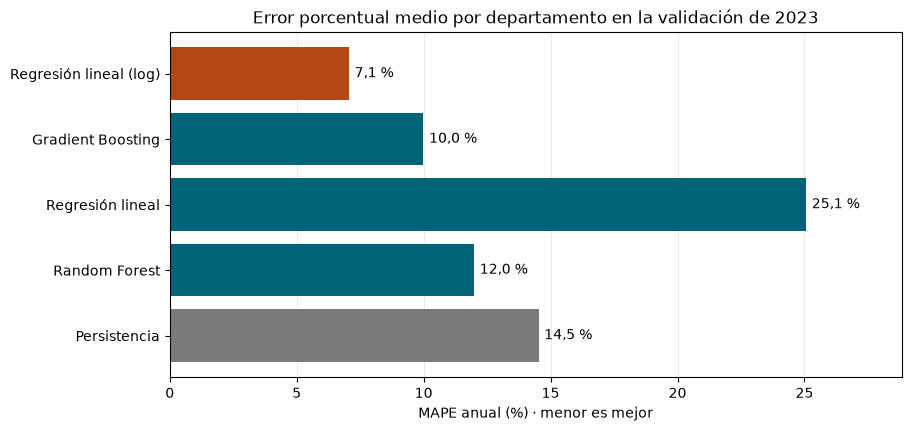

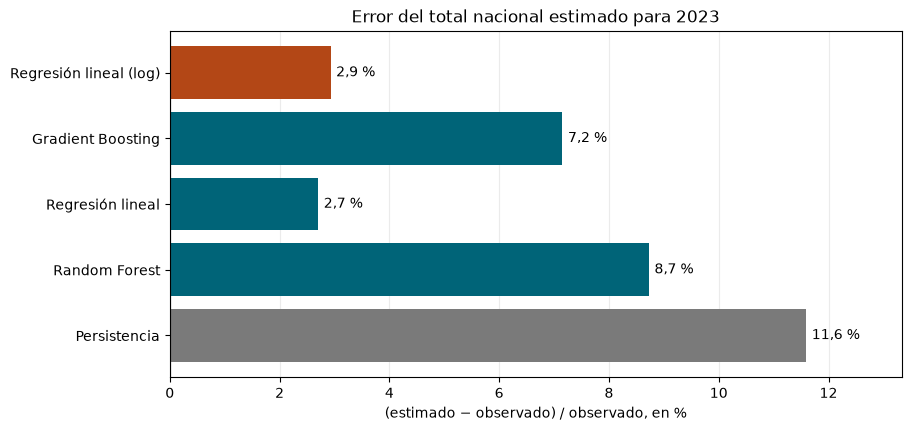

In [9]:
fig, ax = plt.subplots(figsize=(9, 4.2), layout="constrained")
orden = resultados.iloc[::-1]
colores = [NARANJA if m == elegido else (GRIS if m == REFERENCIA else AZUL) for m in orden["Modelo"]]
barras = ax.barh(orden["Modelo"], orden["MAPE anual (%)"], color=colores)
ax.bar_label(barras, labels=[f"{decimal(v)} %" for v in orden["MAPE anual (%)"]], padding=4)
ax.set(title="Error porcentual medio por departamento en la validación de 2023",
       xlabel="MAPE anual (%) · menor es mejor", ylabel="")
ax.margins(x=0.15)
ax.grid(axis="x", alpha=0.25)
ax.set_axisbelow(True)
plt.show()

fig, ax = plt.subplots(figsize=(9, 4.2), layout="constrained")
nacional = resultados.set_index("Modelo")["Error total nacional (%)"].loc[orden["Modelo"]]
barras = ax.barh(nacional.index, nacional, color=colores)
ax.bar_label(barras, labels=[f"{decimal(v)} %" for v in nacional], padding=4)
ax.axvline(0, color="#555555", linewidth=0.8)
ax.set(title="Error del total nacional estimado para 2023",
       xlabel="(estimado − observado) / observado, en %", ylabel="")
ax.margins(x=0.15)
ax.grid(axis="x", alpha=0.25)
ax.set_axisbelow(True)
plt.show()

### Justificación de la elección

**Desde la teoría.** La exploración mostró una caída sostenida de los nacimientos en casi todos los departamentos. Predecir 2024 exige **extrapolar** esa tendencia a un año que nunca se ha visto. Los modelos de árboles (Random Forest y Gradient Boosting) solo pueden devolver valores parecidos a los que vieron al entrenar, así que tienden a "congelar" el nivel de años anteriores. La regresión lineal sí extrapola. En escala logarítmica, además, la tendencia se expresa en porcentaje, lo que es coherente con territorios de tamaños muy distintos.

**Desde los datos.** La tabla y los gráficos anteriores muestran el desempeño de cada modelo en 2023.

#### Elección del modelo según los resultados

**¿Cuál eligieron y por qué?** Se eligió la Regresión lineal en escala logarítmica porque logró el mejor MAE (745 nacimientos) y un excelente MAPE (7,1 %), demostrando que se adapta bien tanto a departamentos grandes como pequeños gracias a que modela cambios porcentuales.

**¿Cuánto mejora frente a la persistencia?** Logra una mejora drástica, reduciendo el error absoluto medio (MAE) en un 58 % (pasando de 1.786 a 745).

**¿Por qué Random Forest y Gradient Boosting sobreestiman el total nacional?** Porque los modelos basados en árboles no pueden extrapolar valores por fuera del rango con el que fueron entrenados. Al enfrentarse a una tendencia de caída histórica inédita, se limitaron a predecir promedios del pasado, sobreestimando fuertemente (+8,7 % Random Forest y +7,2 % Gradient Boosting).

**¿Por qué la regresión lineal simple tiene un MAPE tan alto?** Porque al no usar logaritmos, aplica un mismo efecto absoluto a todos los territorios. Restar 500 nacimientos a Bogotá es un ajuste menor, pero restarle 500 a un departamento que solo tiene 600 destruye la predicción, disparando el error porcentual (25,1 %).

**¿Por qué descartaron la variable de adolescentes?** Porque empíricamente empeoró el desempeño del modelo. Al agregarla, el MAE subió de 745 a 839, lo que indica que introdujo ruido en lugar de poder predictivo.

## E) Entrenamiento del modelo

El modelo seleccionado se vuelve a entrenar con **todos los datos históricos disponibles como objetivo (2021, 2022 y 2023)**, con los rezagos de 2020 a 2022. Así incorpora el último año observado antes de predecir 2024.

In [10]:
modelo_final = clone(CANDIDATOS[elegido]).fit(datos_modelo[VARIABLES], datos_modelo["nacimientos"])
print(f"Modelo final: {elegido}")
print(f"Filas de entrenamiento: {len(datos_modelo)} (33 territorios × 3 años × 12 meses)")

if "lineal" in elegido.lower():
    tuberia = modelo_final.regressor_ if hasattr(modelo_final, "regressor_") else modelo_final
    nombres = tuberia[0].get_feature_names_out()
    coeficientes = pd.Series(tuberia[-1].coef_, index=nombres)
    beta_anio = coeficientes["remainder__anio"]
    if "(log)" in elegido:
        display(Markdown(
            f"Coeficiente del año: **{decimal(beta_anio, 4)}** en escala logarítmica. Equivale a un cambio de "
            f"**{decimal(100 * (np.exp(beta_anio) - 1))} %** por año, manteniendo fijos el departamento, el mes y el rezago."))
        estacional = coeficientes.filter(like="categoricas__mes_")
        estacional.index = estacional.index.str.replace("categoricas__mes_", "", regex=False).astype(int)
        efecto_mes = 100 * (np.exp(estacional - estacional.mean()) - 1)
        tabla_mes = pd.DataFrame({"Mes": [MESES[m - 1] for m in efecto_mes.index], "Efecto frente al mes promedio (%)": efecto_mes.values})
        mostrar(tabla_mes, {"Efecto frente al mes promedio (%)": decimal})
    else:
        display(Markdown(f"Coeficiente del año: **{decimal(beta_anio)}** nacimientos por mes y departamento."))

Modelo final: Regresión lineal (log)
Filas de entrenamiento: 1188 (33 territorios × 3 años × 12 meses)


Coeficiente del año: **-0,0984** en escala logarítmica. Equivale a un cambio de **-9,4 %** por año, manteniendo fijos el departamento, el mes y el rezago.

Mes,Efecto frente al mes promedio (%)
enero,"-0,1"
febrero,"-7,4"
marzo,"3,6"
abril,"-0,7"
mayo,"1,8"
junio,"-1,0"
julio,"0,1"
agosto,"1,6"
septiembre,"3,8"
octubre,"-0,2"


### Interpretación de los coeficientes

**¿Qué significa un −9,4 % anual?** Significa que la tendencia estructural subyacente de la natalidad en Colombia es una contracción de casi el 10 % cada año, aislando y manteniendo constantes el tamaño del departamento, el mes específico y el nivel de nacimientos del año previo.

**¿Coincide con la estacionalidad que vieron en la exploración?** Sí, coincide perfectamente. El modelo aprendió a castigar el pronóstico en febrero (-7,4 %) y a elevarlo en septiembre (+3,8 %) y marzo (+3,6 %), reflejando la realidad observada en las gráficas.

## F) Evaluación del modelo

La evaluación usa la validación de 2023 (entrenando solo con 2021–2022), porque es el único año que sirve de prueba fuera de la muestra.

- **MAE** (error absoluto medio): cuántos nacimientos se equivoca, en promedio, el modelo por departamento en el año.
- **RMSE** (raíz del error cuadrático medio): también en nacimientos, pero castiga más los errores grandes; si es mucho mayor que el MAE, hay pocos departamentos con errores grandes.
- **R²**: proporción de la variación entre departamentos que explica el modelo. Hay que leerlo con cuidado: como los departamentos difieren mucho en tamaño, incluso la persistencia obtiene un R² alto.
- **MAPE**: error porcentual medio; pesa igual a un departamento grande y a uno pequeño.

Modelo,MAE mensual,MAE anual,RMSE anual,R² anual,MAPE anual (%),Error total nacional (%)
Regresión lineal (log),"76,2","745,4","1.044,0","0,9951","7,1","2,9"
Persistencia,"150,8","1.785,7","2.439,1","0,9732","14,5","11,6"


**Departamentos con mayor error porcentual en 2023**

departamento,Observado,Estimado,Error,Error (%)
Guainía,738,1.148,410,"55,5"
Chocó,6.642,7.463,821,"12,4"
Vaupés,690,773,83,"12,0"
Amazonas,903,1.009,106,"11,7"
Cesar,18.144,20.226,2.082,"11,5"
Cauca,14.115,15.510,1.395,"9,9"
Caquetá,5.137,5.607,470,"9,1"
Arauca,3.482,3.777,295,"8,5"


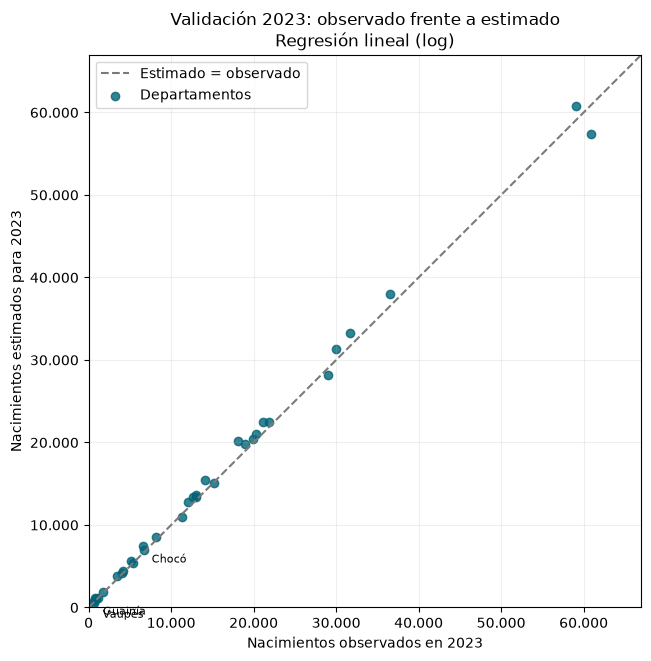

En 2023, **Regresión lineal (log)** tuvo un MAE de **745,4** nacimientos por departamento, un RMSE de **1.044,0**, un R² de **0,9951** y un MAPE de **7,1 %**. El total nacional estimado se desvió **2,9 %**. Sobreestimó **27 de 33** departamentos.

In [11]:
fila = resultados.set_index("Modelo").loc[elegido]
mostrar(resultados.loc[resultados["Modelo"].isin([elegido, REFERENCIA])], FORMATOS)

validacion_anual = (validacion.assign(Estimado=predicciones_val[elegido])
                    .groupby(["codigo", "departamento"], as_index=False)
                    .agg(Observado=("nacimientos", "sum"), Estimado=("Estimado", "sum")))
validacion_anual["Error"] = validacion_anual["Estimado"] - validacion_anual["Observado"]
validacion_anual["Error (%)"] = 100 * validacion_anual["Error"] / validacion_anual["Observado"]
peores = validacion_anual.reindex(validacion_anual["Error (%)"].abs().sort_values(ascending=False).index)
display(Markdown("**Departamentos con mayor error porcentual en 2023**"))
mostrar(peores.head(8).drop(columns="codigo"),
        {"Observado": entero, "Estimado": entero, "Error": entero, "Error (%)": decimal})

fig, ax = plt.subplots(figsize=(7, 6.5), layout="constrained")
limite = 1.1 * validacion_anual[["Observado", "Estimado"]].max().max()
ax.plot([0, limite], [0, limite], "--", color=GRIS, label="Estimado = observado")
ax.scatter(validacion_anual["Observado"], validacion_anual["Estimado"], color=AZUL, alpha=0.8, label="Departamentos")
for _, f in peores.head(3).iterrows():
    ax.annotate(f["departamento"], (f["Observado"], f["Estimado"]), xytext=(6, -12),
                textcoords="offset points", fontsize=8)
ax.set(title=f"Validación 2023: observado frente a estimado\n{elegido}",
       xlabel="Nacimientos observados en 2023", ylabel="Nacimientos estimados para 2023",
       xlim=(0, limite), ylim=(0, limite), aspect="equal")
ax.xaxis.set_major_formatter(eje_miles)
ax.yaxis.set_major_formatter(eje_miles)
ax.grid(alpha=0.2)
ax.legend()
plt.show()

sobre = (validacion_anual["Error"] > 0).sum()
display(Markdown(
    f"En 2023, **{elegido}** tuvo un MAE de **{decimal(fila['MAE anual'])}** nacimientos por departamento, "
    f"un RMSE de **{decimal(fila['RMSE anual'])}**, un R² de **{decimal(fila['R² anual'], 4)}** y un MAPE de "
    f"**{decimal(fila['MAPE anual (%)'])} %**. El total nacional estimado se desvió **{decimal(fila['Error total nacional (%)'])} %**. "
    f"Sobreestimó **{sobre} de 33** departamentos."
))

### Interpretación de la evaluación

**¿Es un error aceptable para planear?** Sí, un MAPE del 7,1 % y una desviación nacional del 2,9 % son márgenes de error altamente aceptables y sólidos para realizar planeación de políticas públicas y presupuestos.

**¿Por qué sobreestima?** Porque la caída del año 2023 (-10,4 %) fue una contracción sorpresivamente fuerte, mucho más acelerada que la tendencia que el modelo había logrado aprender con los datos de 2021 y 2022. Por eso sobreestimó 27 de los 33 departamentos.

**¿Por qué fallan más los departamentos pequeños?** Porque tienen un volumen de nacimientos tan bajo que cualquier pequeña variación aleatoria (unos pocos nacimientos de más o de menos) representa un salto porcentual gigante, lo que eleva dramáticamente el MAPE regional. Es el caso de Guainía (+55,5 %), Vaupés (+12,0 %) y Amazonas (+11,7 %); Chocó (+12,4 %) también tiene un error alto.

**¿Por qué el R² de 0,99 no basta?** Porque en bases de datos con diferencias de escala tan extremas (Bogotá vs. Vaupés), cualquier modelo que simplemente asigne cifras altas a los grandes y bajas a los pequeños obtendrá un R² casi perfecto (incluso la persistencia saca 0,97). No mide bien la verdadera precisión predictiva.

**¿Qué limitaciones hay?** La principal limitación es contar con una ventana histórica tan corta (solo 3 años de entrenamiento y 1 de prueba). Esto impide que el algoritmo diferencie entre un choque temporal y un cambio demográfico definitivo de largo plazo.

## G) Visualización de resultados: predicción para 2024

Se construyen las variables de 2024 con información conocida al cierre de 2023 (los nacimientos de cada departamento y mes en 2023 como rezago) y se predicen los 12 meses de cada departamento. La predicción anual es la suma de los meses, redondeada a enteros.

In [12]:
futuro = panel.loc[panel["anio"].eq(2023), ["codigo", "departamento", "mes", "nacimientos"]].rename(
    columns={"nacimientos": "rezago_12"}).assign(anio=2024)
futuro = futuro.merge(adolescentes_depto, on=["codigo", "anio"], how="left", validate="many_to_one")
assert len(futuro) == 33 * 12 and not futuro[VARIABLES].isna().any().any()
futuro["prediccion"] = np.maximum(modelo_final.predict(futuro[VARIABLES]), 0)

prediccion_2024 = (futuro.groupby(["codigo", "departamento"], as_index=False)["prediccion"].sum()
                   .merge(anual.loc[anual["anio"].eq(2023), ["codigo", "nacimientos"]], on="codigo")
                   .rename(columns={"nacimientos": "Observado 2023", "prediccion": "Predicción 2024"}))
prediccion_2024["Predicción 2024"] = np.floor(prediccion_2024["Predicción 2024"] + 0.5).astype(int)
prediccion_2024["Cambio esperado (%)"] = 100 * (prediccion_2024["Predicción 2024"] / prediccion_2024["Observado 2023"] - 1)
prediccion_2024 = prediccion_2024.sort_values("Predicción 2024", ascending=False, ignore_index=True)
total_2024 = int(prediccion_2024["Predicción 2024"].sum())

tabla_2024 = pd.concat([prediccion_2024.drop(columns="codigo"), pd.DataFrame([{
    "departamento": "Total nacional (33 territorios)", "Observado 2023": anual_nacional[2023],
    "Predicción 2024": total_2024, "Cambio esperado (%)": 100 * (total_2024 / anual_nacional[2023] - 1)}])],
    ignore_index=True).rename(columns={"departamento": "Departamento"})
display(Markdown(f"### Total nacional estimado para 2024: **{entero(total_2024)} nacimientos**"))
mostrar(tabla_2024, {"Observado 2023": entero, "Predicción 2024": entero, "Cambio esperado (%)": decimal})

### Total nacional estimado para 2024: **451.533 nacimientos**

Departamento,Predicción 2024,Observado 2023,Cambio esperado (%)
Antioquia,51.758,59.017,"-12,3"
Bogotá D. C.,51.134,60.912,"-16,1"
Valle del Cauca,32.596,36.514,"-10,7"
Atlántico,28.468,31.727,"-10,3"
Bolívar,26.780,29.953,"-10,6"
Cundinamarca,24.926,29.061,"-14,2"
Santander,19.446,21.890,"-11,2"
Córdoba,19.180,21.080,"-9,0"
La Guajira,18.203,20.333,"-10,5"
Magdalena,17.686,19.865,"-11,0"


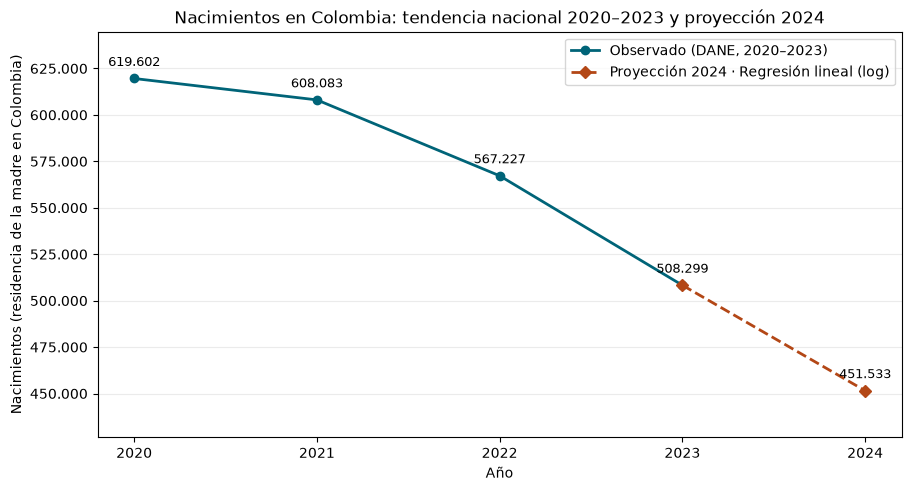

In [13]:
# Gráfico de líneas: tendencia nacional 2020–2023 y proyección 2024
fig, ax = plt.subplots(figsize=(9, 4.8), layout="constrained")
ax.plot(anual_nacional.index, anual_nacional.values, "o-", color=AZUL, linewidth=2, label="Observado (DANE, 2020–2023)")
ax.plot([2023, 2024], [anual_nacional[2023], total_2024], "D--", color=NARANJA, linewidth=2,
        label=f"Proyección 2024 · {elegido}")
for anio, valor in [*anual_nacional.items(), (2024, total_2024)]:
    ax.annotate(entero(valor), (anio, valor), xytext=(0, 9), textcoords="offset points", ha="center", fontsize=9)
ax.set(title="Nacimientos en Colombia: tendencia nacional 2020–2023 y proyección 2024",
       xlabel="Año", ylabel="Nacimientos (residencia de la madre en Colombia)", xticks=[2020, 2021, 2022, 2023, 2024])
ax.yaxis.set_major_formatter(eje_miles)
ax.margins(y=0.15)
ax.grid(axis="y", alpha=0.25)
ax.legend()
plt.show()

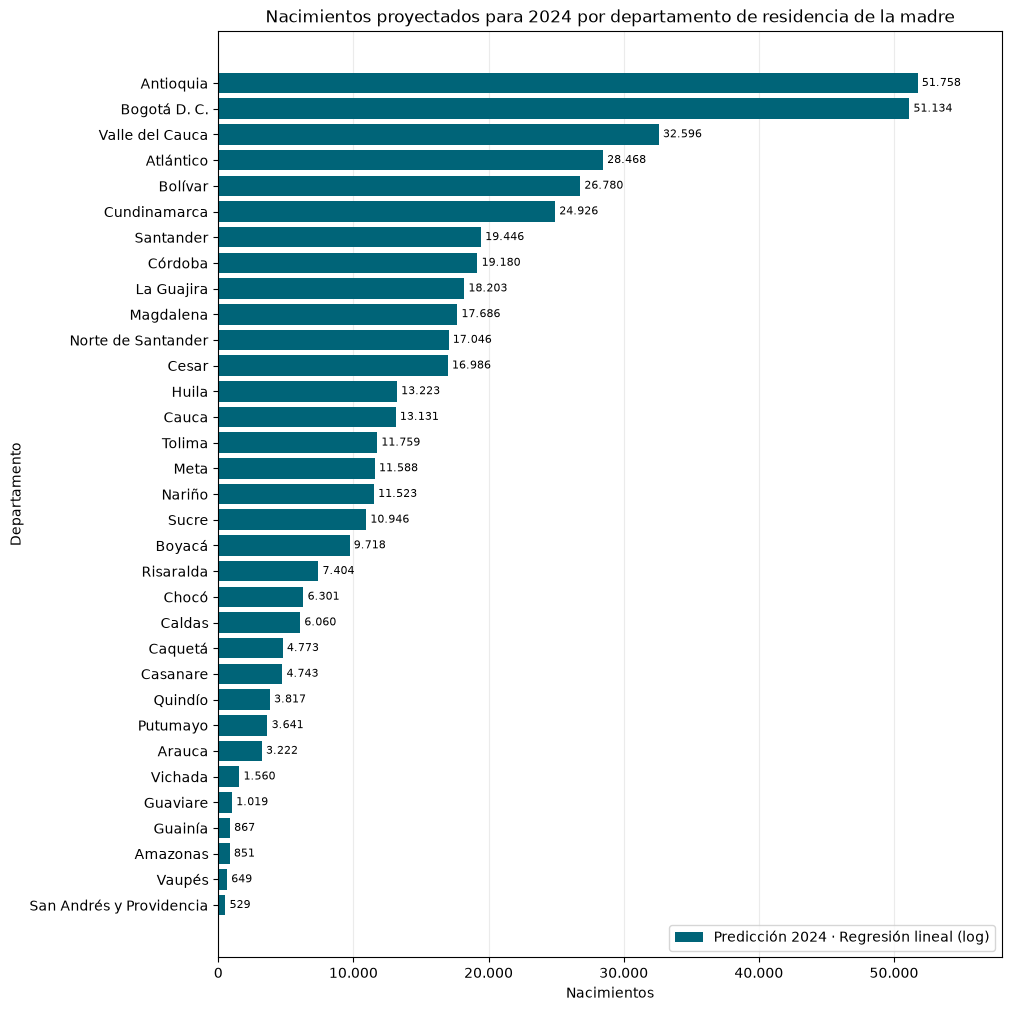

In [14]:
# Gráfico de barras: estimación por departamento para 2024
fig, ax = plt.subplots(figsize=(10, 10), layout="constrained")
barras = ax.barh(prediccion_2024["departamento"], prediccion_2024["Predicción 2024"], color=AZUL,
                 label=f"Predicción 2024 · {elegido}")
ax.bar_label(barras, labels=[entero(v) for v in prediccion_2024["Predicción 2024"]], padding=3, fontsize=8)
ax.invert_yaxis()
ax.set(title="Nacimientos proyectados para 2024 por departamento de residencia de la madre",
       xlabel="Nacimientos", ylabel="Departamento")
ax.xaxis.set_major_formatter(eje_miles)
ax.margins(x=0.12)
ax.grid(axis="x", alpha=0.25)
ax.set_axisbelow(True)
ax.legend(loc="lower right")
plt.show()

### Interpretación de la predicción de 2024

**¿La proyección sigue la tendencia?** Sí, la proyección es matemáticamente coherente y refleja la tendencia aprendida, estimando una agresiva caída total del -11,2 % para 2024.

**¿Es plausible que Antioquia supere a Bogotá?** Hay que tomarlo con cautela. En el acumulado 2020–2023 Bogotá cayó más que Antioquia (−23,2 % frente a −17,8 %), pero en el último año fue al revés: entre 2022 y 2023 Antioquia cayó −11,6 % y Bogotá solo −6,0 %. De hecho, el contraste del anexo muestra que en 2024 Bogotá siguió siendo el territorio con más nacimientos (56.541 frente a 52.171 de Antioquia), así que el cruce que predice el modelo no ocurrió.

**¿Por qué el modelo castiga tanto a Bogotá?** El modelo no tiene una pendiente propia por departamento: aplica a todos el mismo coeficiente del año (−9,4 %). La diferencia de Bogotá sale de su efecto de departamento y de su rezago. Una hipótesis es que su caída de 2020 a 2021 (−15,6 %, la mayor del país ese año), que está dentro de los datos de entrenamiento, empuja hacia abajo su nivel estimado. El anexo confirma que el modelo subestimó a Bogotá (−9,6 %): en 2024 cayó solo −7,2 %.

## H) Conclusiones

In [15]:
cambio_2024 = 100 * (total_2024 / anual_nacional[2023] - 1)
top3 = prediccion_2024.head(3)
participacion_top3 = 100 * top3["Predicción 2024"].sum() / total_2024
display(Markdown(
    f"- **Modelo:** {elegido}, elegido frente a {len(CANDIDATOS) - 1} alternativas y la persistencia por su menor error en la validación de 2023.\n"
    f"- **Precisión (validación 2023):** MAE de {decimal(fila['MAE anual'])} nacimientos por departamento, "
    f"MAPE de {decimal(fila['MAPE anual (%)'])} %, R² de {decimal(fila['R² anual'], 4)} y error del total nacional de "
    f"{decimal(fila['Error total nacional (%)'])} %.\n"
    f"- **Predicción nacional 2024:** {entero(total_2024)} nacimientos en los 33 territorios "
    f"({decimal(cambio_2024)} % frente a 2023).\n"
    f"- **Predicción departamental 2024:** {', '.join(f'{d} ({entero(v)})' for d, v in zip(top3['departamento'], top3['Predicción 2024']))} "
    f"concentran el {decimal(participacion_top3)} % de los nacimientos esperados. La tabla completa está en la sección G."
))

- **Modelo:** Regresión lineal (log), elegido frente a 3 alternativas y la persistencia por su menor error en la validación de 2023.
- **Precisión (validación 2023):** MAE de 745,4 nacimientos por departamento, MAPE de 7,1 %, R² de 0,9951 y error del total nacional de 2,9 %.
- **Predicción nacional 2024:** 451.533 nacimientos en los 33 territorios (-11,2 % frente a 2023).
- **Predicción departamental 2024:** Antioquia (51.758), Bogotá D. C. (51.134), Valle del Cauca (32.596) concentran el 30,0 % de los nacimientos esperados. La tabla completa está en la sección G.

### Conclusiones del grupo

**1. Qué tan efectivo es el modelo.** La regresión lineal logarítmica demostró ser altamente efectiva, logrando modelar el problema de escalas dispares y reduciendo el error en un 58 % respecto al modelo base.

**2. Si 2024 es coherente con el histórico.** A nivel nacional la proyección es coherente, ya que extrapola tanto la tendencia bajista acelerada como el ciclo estacional de los meses. A nivel departamental hay casos que no reproduce bien, como Bogotá, que el modelo ubica por debajo de Antioquia y en realidad siguió primera.

**3. Limitaciones y mejoras.** El modelo mejoraría al incorporar más historia, usar tasas de natalidad (nacimientos por población) en lugar de valores absolutos, y al proporcionar intervalos de confianza para medir la incertidumbre.

**4. Qué aprendió el grupo.** Se evidenció que los algoritmos sofisticados no lineales (Random Forest, Gradient Boosting) no siempre son los mejores, pues tienden a sobreestimar en problemas de series de tiempo que exigen extrapolar tendencias fuera del rango histórico conocido.

## Anexo: contraste con las cifras observadas de 2024

Este anexo **no se usa para entrenar ni para elegir el modelo**. Una vez fijada la predicción, se compara con los nacimientos de 2024 que el DANE publicó en sus cuadros agregados (Cuadro 3: nacimientos por departamento de residencia de la madre). Si la descarga falla, la celda lo informa y el resto del cuaderno no se ve afectado.

In [16]:
URL_2024 = "https://www.dane.gov.co/files/operaciones/EEVV/2026/6-feb-2026/anex-EEVV-NacimientosCuadroAcumulado-2024.xlsx"


def observado_2024():
    from io import BytesIO
    with urlopen(Request(URL_2024, headers={"User-Agent": "Mozilla/5.0"}), timeout=120) as respuesta:
        contenido = BytesIO(respuesta.read())
    with pd.ExcelFile(contenido) as libro:
        hoja = next(h for h in libro.sheet_names if h.lower().replace(" ", "") == "cuadro3")
    contenido.seek(0)
    bruto = pd.read_excel(contenido, sheet_name=hoja, header=None, usecols="A:E", dtype=object)
    bruto.columns = ["codigo", "municipio", "rotulo", "detalle", "total"]
    bruto["codigo"] = bruto["codigo"].astype(str).str.replace(r"\.0$", "", regex=True).str.strip().str.zfill(2)
    filas = bruto.loc[bruto["codigo"].isin(DIVIPOLA)
                      & bruto["detalle"].fillna("").astype(str).str.strip().str.fullmatch("Total(?: Dpto)?", case=False)]
    if filas["codigo"].duplicated().any() or set(filas["codigo"]) != set(DIVIPOLA):
        raise ValueError("El Cuadro 3 no tiene exactamente los 33 territorios.")
    return filas.set_index("codigo")["total"].astype(int).rename("Observado 2024")


try:
    contraste = prediccion_2024.merge(observado_2024(), left_on="codigo", right_index=True, validate="one_to_one")
except Exception as error:
    display(Markdown(f"No fue posible descargar el anexo del DANE ({type(error).__name__}). Se omite el contraste."))
else:
    contraste["Error (%)"] = 100 * (contraste["Predicción 2024"] / contraste["Observado 2024"] - 1)
    obs_total = contraste["Observado 2024"].sum()
    m = metricas(contraste["Observado 2024"], contraste["Predicción 2024"], contraste["codigo"].to_numpy())
    display(Markdown(
        f"Observado 2024 (33 territorios): **{entero(obs_total)}** · predicho: **{entero(total_2024)}** · "
        f"diferencia: **{decimal(100 * (total_2024 / obs_total - 1))} %**. "
        f"MAE por departamento: **{decimal(m['MAE anual'])}** · MAPE: **{decimal(m['MAPE anual (%)'])} %**."))
    mostrar(contraste.drop(columns=["codigo", "Cambio esperado (%)"]).rename(columns={"departamento": "Departamento"})
            .sort_values("Error (%)", key=np.abs, ascending=False),
            {"Observado 2023": entero, "Predicción 2024": entero, "Observado 2024": entero, "Error (%)": decimal})

Observado 2024 (33 territorios): **443.148** · predicho: **451.533** · diferencia: **1,9 %**. MAE por departamento: **816,1** · MAPE: **7,0 %**.

Departamento,Predicción 2024,Observado 2023,Observado 2024,Error (%)
Guainía,867,738,714,"21,4"
Vaupés,649,690,545,"19,1"
Sucre,10.946,11.986,9.537,"14,8"
Cesar,16.986,18.144,14.802,"14,8"
Vichada,1.560,1.700,1.371,"13,8"
San Andrés y Providencia,529,608,601,"-12,0"
Magdalena,17.686,19.865,15.857,"11,5"
Amazonas,851,903,773,"10,1"
Bogotá D. C.,51.134,60.912,56.541,"-9,6"
Bolívar,26.780,29.953,24.559,"9,0"


### Interpretación del contraste con 2024

**¿Qué tan cerca quedó la predicción de lo observado?**
La predicción quedó bastante cerca a nivel nacional: el modelo estimó 451.533 nacimientos y en la realidad se observaron 443.148, lo que equivale a un desfase de apenas +1,9 % (una ligera sobreestimación). A nivel de los departamentos, el margen de error promedio se mantuvo bajo, con un MAE de 816 nacimientos y un MAPE del 7,0 %.

**¿Confirma o contradice la evaluación de 2023?**
La confirma en lo general. El desempeño del modelo al predecir el año 2024 arrojó métricas (MAPE del 7,0 % y MAE de 816) muy similares a las que se obtuvieron durante la validación del 2023 (donde el MAPE fue de 7,1 % y el MAE de 745). Esto indica que el modelo es estable y que el esquema de validación elegido reflejó correctamente cómo se iba a comportar el algoritmo en la realidad.

**¿Qué departamento sorprendió?**
Bogotá: el modelo predijo una caída de −16,1 % y en realidad cayó −7,2 %, por lo que siguió por encima de Antioquia. En porcentaje, los mayores errores siguen estando en los departamentos pequeños, como Guainía (+21,4 %) y Vaupés (+19,1 %).

## Referencias

- Departamento Administrativo Nacional de Estadística [DANE]. (2022). *Estadísticas Vitales – EEVV – 2020* [Conjunto de datos]. https://microdatos.dane.gov.co/index.php/catalog/732
- Departamento Administrativo Nacional de Estadística [DANE]. (⚠ año de publicación). *Estadísticas Vitales – EEVV – 2021* [Conjunto de datos]. https://microdatos.dane.gov.co/index.php/catalog/775
- Departamento Administrativo Nacional de Estadística [DANE]. (⚠ año de publicación). *Estadísticas Vitales – EEVV – 2022* [Conjunto de datos]. https://microdatos.dane.gov.co/index.php/catalog/807
- Departamento Administrativo Nacional de Estadística [DANE]. (2025). *Estadísticas Vitales – EEVV – 2023* [Conjunto de datos]. https://microdatos.dane.gov.co/index.php/catalog/876
- Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., … Duchesnay, É. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830.